# Klasifikasi Uang Kertas Rupiah - Feedforward Neural Network (FNN / MLP 7 Kelas)

## 1. Setup dan Konfigurasi

In [1]:
import os, sys, io, json, math, random, shutil, hashlib, platform, time, warnings
from pathlib import Path
from dataclasses import dataclass, asdict
from concurrent.futures import ThreadPoolExecutor

# Impor TensorFlow sebelum sklearn untuk stabilitas di environment Windows
import tensorflow as tf
from tensorflow.keras import layers, regularizers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw): return x

warnings.filterwarnings('ignore', category=UserWarning)

IN_COLAB = Path('/content').is_dir() and platform.system() == 'Linux'
QUICK_MODE = os.environ.get('FNN_QUICK', '') == '1'

# Direktori kerja ASCII-only untuk resize dan cache berat
WORK_DIR = Path('/content/fnn_work') if IN_COLAB else Path('C:/fnn_work')
WORK_DIR.mkdir(parents=True, exist_ok=True)

# Direktori hasil (lokal terhadap notebook)
BASE_DIR = Path('.')
RESULTS = BASE_DIR / 'results'
RESULTS.mkdir(parents=True, exist_ok=True)

@dataclass(frozen=True)
class Config:
    seed: int = 42
    classes: tuple = ('idr_1000', 'idr_2000', 'idr_5000', 'idr_10000',
                      'idr_20000', 'idr_50000', 'idr_100000')
    img_size: tuple = (224, 224)
    split_ratios: tuple = (0.70, 0.15, 0.15)
    n_group_folds: int = 20
    near_dup_threshold: int = 6
    resize_mode: str = 'pad'
    n_workers: int = min(8, os.cpu_count() or 2)
    batch_size: int = 32
    baseline_epochs: int = 15
    tuning_epochs: int = 30
    baseline_lr: float = 1e-3
    tuning_lr: float = 5e-4
    patience: int = 8
    repo_url: str = 'https://github.com/mkaspulanwar/rupiah-banknotes-dataset.git'
    data_root_override: str = os.environ.get(
        'RUPIAH_DATA_ROOT',
        'C:/Users/Bunga Alyssa/OneDrive/文档/DS/smt  7/deep l/uas/frontend/rupiah-banknotes-dataset-main'
        if not IN_COLAB else '')
    quick_test: bool = QUICK_MODE

cfg = Config()
CLASSES = list(cfg.classes)
IMG_SIZE = tuple(cfg.img_size)
SEED = cfg.seed

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False})

def pretty(c):
    return 'Rp ' + f"{int(c.split('_')[1]):,}".replace(',', '.')

print('Konfigurasi Eksperimen FNN:')
for k, v in asdict(cfg).items():
    print(f'  {k:22s}: {v}')

print('\nLingkungan:')
print(f'  OS          : {platform.system()} {platform.release()}')
print(f'  Python      : {platform.python_version()}')
print(f'  TensorFlow  : {tf.__version__}')
print(f'  NumPy       : {np.__version__}')
print(f'  Pandas      : {pd.__version__}')
print(f'  GPU         : {[g.name for g in tf.config.list_physical_devices("GPU")] or "CPU"}')
print(f'  WORK_DIR    : {WORK_DIR.resolve()}')
print(f'  RESULTS_DIR : {RESULTS.resolve()}')
if cfg.quick_test:
    print('\n>>> PERINGATAN: MODE UJI CEPAT (FNN_QUICK=1) AKTIF. HASIL TIDAK VALID UNTUK LAPORAN FINAL. <<<')

Konfigurasi Eksperimen FNN:
  seed                  : 42
  classes               : ('idr_1000', 'idr_2000', 'idr_5000', 'idr_10000', 'idr_20000', 'idr_50000', 'idr_100000')
  img_size              : (224, 224)
  split_ratios          : (0.7, 0.15, 0.15)
  n_group_folds         : 20
  near_dup_threshold    : 6
  resize_mode           : pad
  n_workers             : 8
  batch_size            : 32
  baseline_epochs       : 15
  tuning_epochs         : 30
  baseline_lr           : 0.001
  tuning_lr             : 0.0005
  patience              : 8
  repo_url              : https://github.com/mkaspulanwar/rupiah-banknotes-dataset.git
  data_root_override    : C:/Users/Bunga Alyssa/OneDrive/文档/DS/smt  7/deep l/uas/frontend/rupiah-banknotes-dataset-main
  quick_test            : False

Lingkungan:
  OS          : Windows 11
  Python      : 3.12.10
  TensorFlow  : 2.16.1
  NumPy       : 1.26.4
  Pandas      : 2.3.3
  GPU         : CPU
  WORK_DIR    : C:\fnn_work
  RESULTS_DIR : C:\fnn_work\resu

## 2. Inventaris Dataset dan Audit Kualitas Gambar

In [2]:
import subprocess

def run_cmd(cmd):
    return subprocess.run(cmd, check=True, capture_output=True, text=True).stdout.strip()

if cfg.data_root_override and Path(cfg.data_root_override).exists():
    repo = Path(cfg.data_root_override)
    DATASET_COMMIT = 'tidak diketahui (salinan ZIP lokal)'
    print(f'Menggunakan salinan ZIP lokal: {repo}')
else:
    repo = WORK_DIR / 'rupiah-banknotes-dataset'
    if not repo.exists():
        print('Meng-clone dataset dari GitHub...')
        run_cmd(['git', 'clone', '--depth', '1', cfg.repo_url, str(repo)])
    try:
        DATASET_COMMIT = run_cmd(['git', '-C', str(repo), 'rev-parse', 'HEAD'])
    except Exception:
        DATASET_COMMIT = 'tidak diketahui'

candidates = [repo] + [d for d in repo.glob('*') if d.is_dir() and not d.name.startswith('.')] \
                    + [d for d in repo.glob('*/*') if d.is_dir() and not d.parent.name.startswith('.')]
DATA_ROOT = next((d for d in candidates if all((d / c).is_dir() for c in CLASSES)), None)
if DATA_ROOT is None:
    raise FileNotFoundError('Folder 7 kelas tidak ditemukan di: ' + str(list(repo.iterdir())))

IMG_EXT = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
excluded_dirs = {n: sum(1 for p in (DATA_ROOT / n).rglob('*') if p.suffix.lower() in IMG_EXT)
                 for n in ('idr_mix', 'test') if (DATA_ROOT / n).is_dir()}

print(f'DATA_ROOT      : {DATA_ROOT.resolve()}')
print(f'Dataset commit : {DATASET_COMMIT}')
print(f'Folder di luar 7 kelas (tidak dipakai): {excluded_dirs or "tidak ada"}')

Menggunakan salinan ZIP lokal: C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\rupiah-banknotes-dataset-main
DATA_ROOT      : C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\rupiah-banknotes-dataset-main
Dataset commit : tidak diketahui (salinan ZIP lokal)
Folder di luar 7 kelas (tidak dipakai): {'idr_mix': 143, 'test': 0}


Menganalisis gambar:   0%|          | 0/1249 [00:00<?, ?it/s]

Selesai audit 1249 gambar dalam 14.5 detik
Valid / Rusak           : 1249 / 0
Rasio kelas maks / min  : 1.29

Distribusi per kelas:


,jumlah,persen
label,,
idr_1000,166,13.3
idr_2000,178,14.3
idr_5000,167,13.4
idr_10000,156,12.5
idr_20000,189,15.1
idr_50000,202,16.2
idr_100000,191,15.3


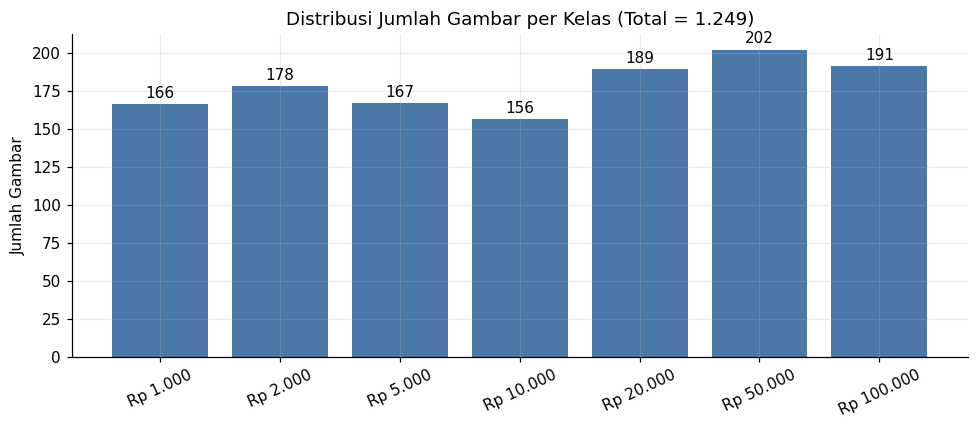

In [3]:
def laplacian_variance(gray):
    g = gray.astype(np.float32)
    lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    return float(lap.var())

def dhash64(gray_img):
    a = np.asarray(gray_img.resize((9, 8), Image.Resampling.LANCZOS), dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    h = 0
    for b in bits:
        h = (h << 1) | int(b)
    return h

def analyze_image(item):
    path, cls = item
    rec = {'path': str(path), 'filename': path.name, 'label': cls, 'valid': False, 'error': None}
    try:
        data = path.read_bytes()
        sha = hashlib.sha256(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            fmt, mode0 = im.format, im.mode
            orientation = im.getexif().get(0x0112, 1)
            w, h = im.size
            if orientation in (5, 6, 7, 8):
                w, h = h, w
            if w < 1 or h < 1:
                raise ValueError('Dimensi tidak valid')
            im.draft('RGB', (448, 448))
            rgb = ImageOps.exif_transpose(im).convert('RGB')
        gray = rgb.convert('L').resize(IMG_SIZE, Image.Resampling.BOX)
        g = np.asarray(gray, dtype=np.float32)
        rec.update(valid=True, width=w, height=h, mode=mode0, format=fmt,
                   aspect_ratio=w / h, file_kb=len(data) / 1024, sha256=sha,
                   brightness=float(g.mean()), contrast=float(g.std()),
                   blur_laplacian=laplacian_variance(g),
                   glare_ratio=float((g >= 250).mean()),
                   dhash=f'{dhash64(gray):016x}')
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'
    return rec

files = [(p, cls) for cls in CLASSES
         for p in sorted((DATA_ROOT / cls).rglob('*'))
         if p.is_file() and p.suffix.lower() in IMG_EXT]
if not files:
    raise RuntimeError('Tidak ada berkas gambar yang ditemukan!')

t0 = time.time()
with ThreadPoolExecutor(cfg.n_workers) as ex:
    records = list(tqdm(ex.map(analyze_image, files), total=len(files), desc='Menganalisis gambar'))

inventory = pd.DataFrame(records)
valid = inventory[inventory.valid].copy().reset_index(drop=True)
valid[['width', 'height']] = valid[['width', 'height']].astype(int)
valid['orientation'] = np.where(valid.width >= valid.height, 'landscape', 'portrait')

n_bad = int((~inventory.valid).sum())
per_class = valid.label.value_counts().reindex(CLASSES, fill_value=0)

print(f'Selesai audit {len(files)} gambar dalam {time.time() - t0:.1f} detik')
print(f'Valid / Rusak           : {len(valid)} / {n_bad}')
print(f'Rasio kelas maks / min  : {per_class.max() / per_class.min():.2f}')
print('\nDistribusi per kelas:')
display(per_class.rename('jumlah').to_frame().assign(
    persen=lambda d: (d.jumlah / d.jumlah.sum() * 100).round(1)))

# Ringkasan visual distribusi kelas
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar([pretty(c) for c in CLASSES], per_class.values, color='#4C78A8')
ax.bar_label(bars, padding=2)
ax.set(title='Distribusi Jumlah Gambar per Kelas (Total = 1.249)', ylabel='Jumlah Gambar')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
fig.savefig(RESULTS / 'eda_class_distribution.png', dpi=160)
plt.show()

## 3. Duplikat dan Kebocoran Data

In [4]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

# 3.1 Duplikat persis
hash_nlabels = valid.groupby('sha256').label.nunique()
conflict_hashes = set(hash_nlabels[hash_nlabels > 1].index)
is_conflict = valid.sha256.isin(conflict_hashes)
is_exact_copy = valid.duplicated('sha256', keep='first') & ~is_conflict

excluded = pd.concat([
    valid[is_conflict].assign(reason='label_konflik'),
    valid[is_exact_copy].assign(reason='duplikat_persis'),
])[['path', 'label', 'sha256', 'reason']]
clean = valid[~is_conflict & ~is_exact_copy].reset_index(drop=True)

print(f'Gambar dikeluarkan (duplikat persis / konflik) : {len(excluded)}')
print(f'Gambar unik bersih digunakan                   : {len(clean)}')
excluded.to_csv(RESULTS / 'excluded_files.csv', index=False)

# 3.2 Near-duplicate grouping via dHash 64-bit
POP8 = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

def hamming_matrix(h):
    x = np.bitwise_xor(h[:, None], h[None, :])
    return POP8[x.view(np.uint8).reshape(len(h), len(h), 8)].sum(axis=2, dtype=np.int16)

h = np.array([int(x, 16) for x in clean.dhash], dtype=np.uint64)
D = hamming_matrix(h)
lab = clean.label.to_numpy(dtype=object)
same_label = lab[:, None] == lab[None, :]
np.fill_diagonal(same_label, False)
D_same = np.where(same_label, D, 65)
D_cross = np.where(~same_label, D, 65)

THR = cfg.near_dup_threshold
n_groups, group_id = connected_components(csr_matrix(D_same <= THR), directed=False)
clean['group_id'] = group_id
sizes = clean.group_id.value_counts()
in_multi = int(sizes[sizes > 1].sum())
n_cross = int(np.triu(D_cross <= THR, k=1).sum())

print(f'Jumlah grup near-duplicate               : {n_groups} (dari {len(clean)} gambar)')
print(f'Grup berisi >1 gambar                    : {(sizes > 1).sum()} ({in_multi} gambar, {in_multi/len(clean):.1%})')
print(f'Ukuran grup terbesar                     : {sizes.max()}')
print(f'Pasangan beda kelas jarak <= {THR}       : {n_cross}')

clean[['path', 'label', 'sha256', 'dhash', 'group_id']].to_csv(RESULTS / 'near_duplicate_groups.csv', index=False)

Gambar dikeluarkan (duplikat persis / konflik) : 0
Gambar unik bersih digunakan                   : 1249
Jumlah grup near-duplicate               : 1126 (dari 1249 gambar)
Grup berisi >1 gambar                    : 64 (187 gambar, 15.0%)
Ukuran grup terbesar                     : 14
Pasangan beda kelas jarak <= 6       : 12


## 4. Split Stratified dan Group-Aware (70/15/15)

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

REF_CNN = {
    'total_valid': 1249, 'groups': 1126,
    'train': 894, 'val': 176, 'test': 179,
    'per_class': {
        'idr_1000':   (130, 15, 21),
        'idr_2000':   (127, 27, 24),
        'idr_5000':   (111, 26, 30),
        'idr_10000':  (111, 22, 23),
        'idr_20000':  (135, 29, 25),
        'idr_50000':  (149, 27, 26),
        'idr_100000': (131, 30, 30),
    }
}

def grouped_stratified_split(frame, ratios, n_folds, seed):
    fold_counts = [r * n_folds for r in ratios]
    n_tr, n_va, _ = (round(c) for c in fold_counts)
    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    fold = np.empty(len(frame), dtype=int)
    for k, (_, idx) in enumerate(sgkf.split(frame, frame.label, frame.group_id)):
        fold[idx] = k
    return np.where(fold < n_tr, 'train', np.where(fold < n_tr + n_va, 'val', 'test'))

split_df = clean.copy()
split_df['split'] = grouped_stratified_split(split_df, cfg.split_ratios, cfg.n_group_folds, SEED)

# Assertions wajib anti-kebocoran
assert (split_df.groupby('group_id').split.nunique() == 1).all(), 'Ada group_id yang terpecah lintas split!'
sets = {s: set(split_df.loc[split_df.split == s, 'sha256']) for s in ('train', 'val', 'test')}
assert not (sets['train'] & sets['val'] or sets['train'] & sets['test'] or sets['val'] & sets['test']), \
    'Ada sha256 yang melintasi split!'
print('VERIFIKASI ANTI-KEBOCORAN: LULUS (Semua group_id dan SHA256 terisolasi)')

counts = pd.crosstab(split_df.label, split_df.split).reindex(CLASSES)[['train', 'val', 'test']]
counts['total'] = counts.sum(axis=1)

print('\n=== Perbandingan Angka Acuan (Custom CNN) vs Aktual ===')
print(f"{'Metrik':<20} {'Acuan CNN':>12} {'Aktual FNN':>12} {'Selisih':>10}")
print('-' * 56)
print(f"{'Total valid':<20} {REF_CNN['total_valid']:>12} {len(valid):>12} {len(valid)-REF_CNN['total_valid']:>+10}")
print(f"{'Total group':<20} {REF_CNN['groups']:>12} {n_groups:>12} {n_groups-REF_CNN['groups']:>+10}")
for s in ('train', 'val', 'test'):
    act_s = int((split_df.split == s).sum())
    ref_s = REF_CNN[s]
    print(f"{'Split ' + s:<20} {ref_s:>12} {act_s:>12} {act_s-ref_s:>+10}")

all_match = True
print('\nRincian per kelas (train / val / test):')
for c in CLASSES:
    ref_t = REF_CNN['per_class'][c]
    act_t = (int(counts.loc[c, 'train']), int(counts.loc[c, 'val']), int(counts.loc[c, 'test']))
    cocok = 'SESUAI' if ref_t == act_t else 'BEDA'
    if ref_t != act_t: all_match = False
    print(f"  {c:<12}: acuan={ref_t} | aktual={act_t} -> {cocok}")

if all_match:
    print('\nKESIMPULAN SPLIT: 100% IDENTIK dengan acuan Custom CNN. Perbandingan performa sepenuhnya apel-dengan-apel.')
else:
    print('\nPERINGATAN: Terdapat perbedaan split dengan acuan. Catat di laporan.')

VERIFIKASI ANTI-KEBOCORAN: LULUS (Semua group_id dan SHA256 terisolasi)

=== Perbandingan Angka Acuan (Custom CNN) vs Aktual ===
Metrik                  Acuan CNN   Aktual FNN    Selisih
--------------------------------------------------------
Total valid                  1249         1249         +0
Total group                  1126         1126         +0
Split train                   894          894         +0
Split val                     176          176         +0
Split test                    179          179         +0

Rincian per kelas (train / val / test):
  idr_1000    : acuan=(130, 15, 21) | aktual=(130, 15, 21) -> SESUAI
  idr_2000    : acuan=(127, 27, 24) | aktual=(127, 27, 24) -> SESUAI
  idr_5000    : acuan=(111, 26, 30) | aktual=(111, 26, 30) -> SESUAI
  idr_10000   : acuan=(111, 22, 23) | aktual=(111, 22, 23) -> SESUAI
  idr_20000   : acuan=(135, 29, 25) | aktual=(135, 29, 25) -> SESUAI
  idr_50000   : acuan=(149, 27, 26) | aktual=(149, 27, 26) -> SESUAI
  idr_10000

## 5. Resize 224×224 dan Caching ke WORK_DIR

In [6]:
OUT_ROOT = WORK_DIR / 'rupiah_processed'

def preprocess_image(src, dst, size=IMG_SIZE, mode=cfg.resize_mode):
    with Image.open(src) as im:
        im.draft('RGB', (size[0] * 2, size[1] * 2))
        img = ImageOps.exif_transpose(im).convert('RGB')
    if mode == 'pad':
        resized = ImageOps.contain(img, size, method=Image.Resampling.LANCZOS)
        out = Image.new('RGB', size, (0, 0, 0))
        out.paste(resized, ((size[0] - resized.width) // 2, (size[1] - resized.height) // 2))
    elif mode == 'stretch':
        out = img.resize(size, Image.Resampling.LANCZOS)
    else:
        raise ValueError(f'resize_mode tidak dikenal: {mode}')
    dst.parent.mkdir(parents=True, exist_ok=True)
    out.save(dst, format='JPEG', quality=95)

for s in ('train', 'val', 'test'):
    if (OUT_ROOT / s).exists():
        shutil.rmtree(OUT_ROOT / s)

split_df = split_df.reset_index(drop=True)
split_df['processed_path'] = [
    str(OUT_ROOT / r.split / r.label / f'{i:05d}_{r.sha256[:10]}.jpg')
    for i, r in enumerate(split_df.itertuples())]

jobs = list(zip(split_df.path, map(Path, split_df.processed_path)))
t0 = time.time()
with ThreadPoolExecutor(cfg.n_workers) as ex:
    list(tqdm(ex.map(lambda a: preprocess_image(*a), jobs), total=len(jobs), desc='Preprocessing'))
print(f'Selesai resize {len(jobs)} gambar dalam {time.time() - t0:.1f} detik')

def check_processed(p):
    with Image.open(p) as im:
        return im.size, im.mode

with ThreadPoolExecutor(cfg.n_workers) as ex:
    info = list(ex.map(check_processed, split_df.processed_path))

assert all(s == IMG_SIZE for s, _ in info), 'Ada gambar dengan ukuran bukan 224x224!'
assert all(m == 'RGB' for _, m in info), 'Ada gambar bukan RGB!'
for s in ('train', 'val', 'test'):
    n_disk = sum(1 for _ in (OUT_ROOT / s).rglob('*.jpg'))
    assert n_disk == (split_df.split == s).sum(), f'Jumlah berkas disk {s} tidak cocok dengan split!'
print('Validasi preprocessing OK: 100% gambar 224x224 RGB tanpa kesalahan.')

split_df[['path', 'processed_path', 'label', 'sha256', 'group_id', 'split']].to_csv(
    WORK_DIR / 'split_manifest.csv', index=False)
(RESULTS / 'class_mapping.json').write_text(
    json.dumps({i: c for i, c in enumerate(CLASSES)}, indent=2), encoding='utf-8')

Preprocessing:   0%|          | 0/1249 [00:00<?, ?it/s]

Selesai resize 1249 gambar dalam 15.8 detik


Validasi preprocessing OK: 100% gambar 224x224 RGB tanpa kesalahan.


140

## 6. Pipeline tf.data dan Augmentasi

In [7]:
def make_ds(split_name, training):
    raw = tf.keras.utils.image_dataset_from_directory(
        str(OUT_ROOT / split_name),
        labels='inferred', label_mode='int',
        class_names=CLASSES,
        image_size=IMG_SIZE,
        batch_size=None,
        shuffle=False)
    paths = list(raw.file_paths)
    ds = raw.cache()
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(cfg.batch_size).prefetch(AUTOTUNE), paths

train_ds, train_paths = make_ds('train', True)
val_ds, val_paths = make_ds('val', False)
test_ds, test_paths = make_ds('test', False)

for name, ds, paths in (('val', val_ds, val_paths), ('test', test_ds, test_paths)):
    y = np.concatenate([b.numpy() for _, b in ds])
    assert len(y) == len(paths) and all(CLASSES[k] == Path(p).parent.name for k, p in zip(y, paths)), \
        f'Label {name} tidak selaras dengan file_paths!'
print('Sanity check pipeline: Label dan daftar berkas val/test selaras 100%.')

# Cek rasio ketidakseimbangan kelas
train_counts = split_df[split_df.split == 'train'].label.value_counts().reindex(CLASSES)
imbalance = train_counts.max() / train_counts.min()
USE_CLASS_WEIGHT = bool(imbalance > 1.5)
CLASS_WEIGHT = {i: float(train_counts.sum() / (len(CLASSES) * train_counts[c]))
                for i, c in enumerate(CLASSES)}
print(f'Rasio kelas di train: {imbalance:.2f} -> Class weight '
      f'{"DIPAKAI" if USE_CLASS_WEIGHT else "TIDAK DIPAKAI (rasio <= 1.5)"}')

def build_augmentation():
    return tf.keras.Sequential([
        layers.RandomRotation(0.05, fill_mode='constant', fill_value=0.0),
        layers.RandomZoom(0.10, fill_mode='constant', fill_value=0.0),
        layers.RandomTranslation(0.05, 0.05, fill_mode='constant', fill_value=0.0),
        layers.RandomContrast(0.15),
        layers.RandomBrightness(0.15, value_range=(0, 255)),
    ], name='augmentation_train_only')

N_TRAIN, N_VAL, N_TEST = len(train_paths), len(val_paths), len(test_paths)
print(f'Data terkonfirmasi: Train = {N_TRAIN}, Validation = {N_VAL}, Test = {N_TEST}')

Found 894 files belonging to 7 classes.


Found 176 files belonging to 7 classes.


Found 179 files belonging to 7 classes.


Sanity check pipeline: Label dan daftar berkas val/test selaras 100%.
Rasio kelas di train: 1.34 -> Class weight TIDAK DIPAKAI (rasio <= 1.5)
Data terkonfirmasi: Train = 894, Validation = 176, Test = 179


## 7. FNN Baseline - dari Paper (Aprillia dkk., 2024)

Model: "fnn_baseline_paper"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_224 (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │    19,267,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_7 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,268,615 (73.50 MB)

 Trainable params: 19,268,615 (73.50 MB)

 Non-trainable params: 0 (0.00 B)


Total Parameter Baseline Paper : 19,268,615
Ukuran Model (float32)        : 73.50 MB
Epoch 1/15


... (25 outputs left out)

Epoch 14/15


28/28 - 6s - 229ms/step - accuracy: 0.2204 - loss: 1.8916 - top2: 0.4362 - val_accuracy: 0.1989 - val_loss: 1.8758 - val_top2: 0.4659


Epoch 15/15


28/28 - 7s - 234ms/step - accuracy: 0.2260 - loss: 1.8706 - top2: 0.4698 - val_accuracy: 0.1989 - val_loss: 1.8786 - val_top2: 0.4659


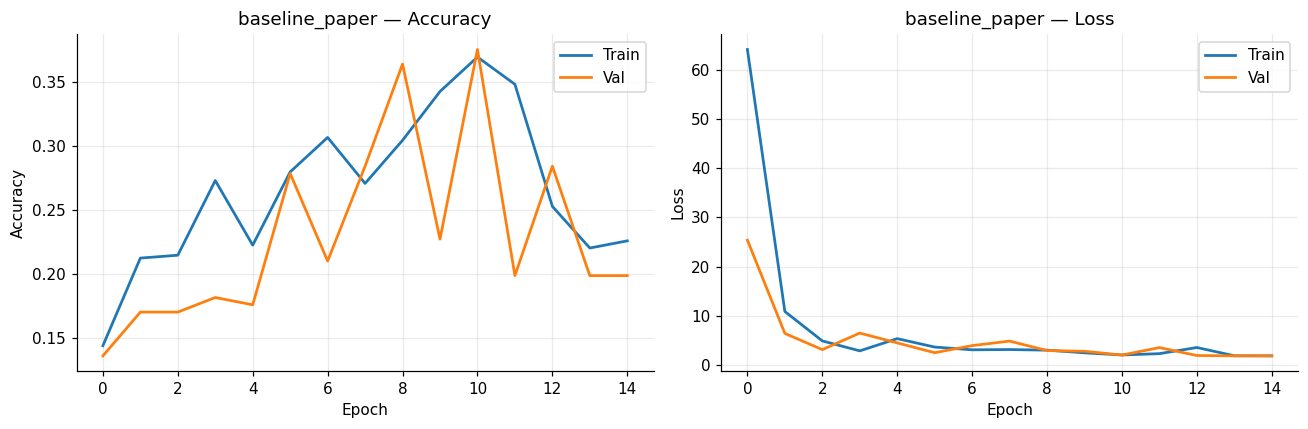


[fnn_baseline_paper] Val Accuracy: 37.50% (95% CI 30.7%-44.8%) | Val Loss: 1.8758


In [8]:
def wilson_ci(k, n, z=1.96):
    if n == 0: return 0.0, 1.0
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    margin = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return max(0.0, centre - margin), min(1.0, centre + margin)

def plot_history(hist, name, out_dir):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric, title in zip(axes, ['accuracy', 'loss'], ['Accuracy', 'Loss']):
        ax.plot(hist.history[metric], label='Train', lw=1.8)
        ax.plot(hist.history[f'val_{metric}'], label='Val', lw=1.8)
        ax.set(title=f'{name} - {title}', xlabel='Epoch', ylabel=title)
        ax.legend()
    plt.tight_layout()
    fig.savefig(out_dir / f'history_{name}.png', dpi=150)
    plt.show()

runs = {}

def build_fnn_baseline_paper():
    inp = tf.keras.Input(shape=(*IMG_SIZE, 3), name='input_224')
    x = layers.Rescaling(1./255, name='rescaling')(inp)
    x = layers.Flatten(name='flatten')(x)
    x = layers.Dense(128, activation='relu', name='dense_128')(x)
    out = layers.Dense(len(CLASSES), activation='softmax', name='output_7')(x)
    model = tf.keras.Model(inp, out, name='fnn_baseline_paper')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(cfg.baseline_lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=2, name='top2')])
    return model

m_base = build_fnn_baseline_paper()
m_base.summary()
n_params_base = m_base.count_params()
print(f'\nTotal Parameter Baseline Paper : {n_params_base:,}')
print(f'Ukuran Model (float32)        : {n_params_base * 4 / (1024**2):.2f} MB')

epochs_bl = 2 if cfg.quick_test else cfg.baseline_epochs
tf.keras.utils.set_random_seed(SEED)
t0 = time.time()
hist_bl = m_base.fit(
    train_ds, validation_data=val_ds,
    epochs=epochs_bl,
    class_weight=CLASS_WEIGHT if USE_CLASS_WEIGHT else None,
    verbose=2)
train_sec_bl = time.time() - t0

plot_history(hist_bl, 'baseline_paper', RESULTS)
pd.DataFrame(hist_bl.history).to_csv(RESULTS / 'history_baseline_paper.csv', index=False)

val_acc_bl = float(max(hist_bl.history['val_accuracy']))
val_top2_bl = float(max(hist_bl.history['val_top2']))
val_loss_bl = float(min(hist_bl.history['val_loss']))
best_ep_bl = int(np.argmax(hist_bl.history['val_accuracy'])) + 1
lo_bl, hi_bl = wilson_ci(round(val_acc_bl * N_VAL), N_VAL)

runs['fnn_baseline_paper'] = {
    'model': m_base, 'history': hist_bl,
    'val_accuracy': val_acc_bl, 'val_top2': val_top2_bl, 'val_loss': val_loss_bl,
    'best_epoch': best_ep_bl, 'epochs_ran': epochs_bl,
    'n_params': n_params_base, 'train_sec': train_sec_bl,
    'val_ci': (lo_bl, hi_bl), 'augmentation': False, 'name': 'fnn_baseline_paper',
}
print(f'\n[fnn_baseline_paper] Val Accuracy: {val_acc_bl:.2%} (95% CI {lo_bl:.1%}-{hi_bl:.1%}) | Val Loss: {val_loss_bl:.4f}')

## 8. Tuning Arsitektur FNN dan Regularisasi


Melatih Model: fnn_tuned_no_aug


Epoch 1/30


28/28 - 7s - 245ms/step - accuracy: 0.3322 - loss: 2.1087 - top2: 0.5123 - val_accuracy: 0.1591 - val_loss: 20.1100 - val_top2: 0.2898 - learning_rate: 5.0000e-04


Epoch 2/30


28/28 - 3s - 113ms/step - accuracy: 0.4329 - loss: 1.6900 - top2: 0.6655 - val_accuracy: 0.1591 - val_loss: 22.1371 - val_top2: 0.3011 - learning_rate: 5.0000e-04


Epoch 3/30


... (47 outputs left out)


Epoch 26: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.


28/28 - 3s - 112ms/step - accuracy: 0.8758 - loss: 0.5187 - top2: 0.9664 - val_accuracy: 0.2727 - val_loss: 4.5087 - val_top2: 0.4318 - learning_rate: 2.5000e-04


Epoch 26: early stopping


Restoring model weights from the end of the best epoch: 18.


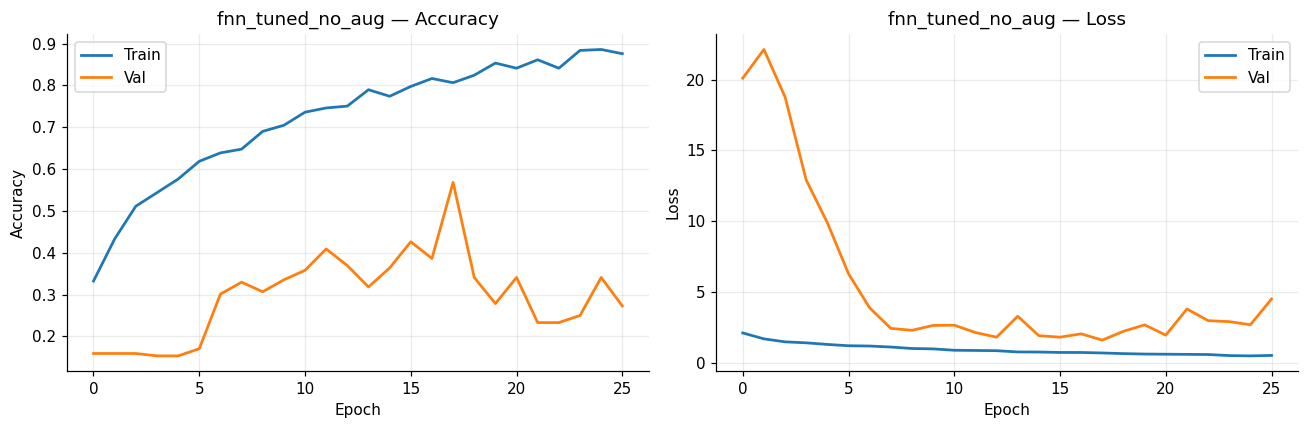

[fnn_tuned_no_aug] Val Acc: 56.82% (95% CI 49.4%-63.9%) | Val Loss: 1.6018 | Best Epoch: 18/26 | Params: 6,460,679 (86s)

Melatih Model: fnn_tuned_with_aug
Epoch 1/30


28/28 - 8s - 280ms/step - accuracy: 0.1779 - loss: 2.4574 - top2: 0.3389 - val_accuracy: 0.1534 - val_loss: 13.0881 - val_top2: 0.3011 - learning_rate: 5.0000e-04


Epoch 2/30


28/28 - 3s - 123ms/step - accuracy: 0.2058 - loss: 2.2930 - top2: 0.3591 - val_accuracy: 0.1477 - val_loss: 6.1252 - val_top2: 0.3011 - learning_rate: 5.0000e-04


Epoch 3/30


28/28 - 3s - 114ms/step - accuracy: 0.2427 - loss: 2.1734 - top2: 0.4385 - val_accuracy: 0.1534 - val_loss: 8.5187 - val_top2: 0.3011 - learning_rate: 5.0000e-04


... (10 outputs left out)


Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.


28/28 - 3s - 113ms/step - accuracy: 0.3110 - loss: 1.9475 - top2: 0.5268 - val_accuracy: 0.3523 - val_loss: 1.7410 - val_top2: 0.5739 - learning_rate: 2.5000e-04


Epoch 8: early stopping


Restoring model weights from the end of the best epoch: 1.


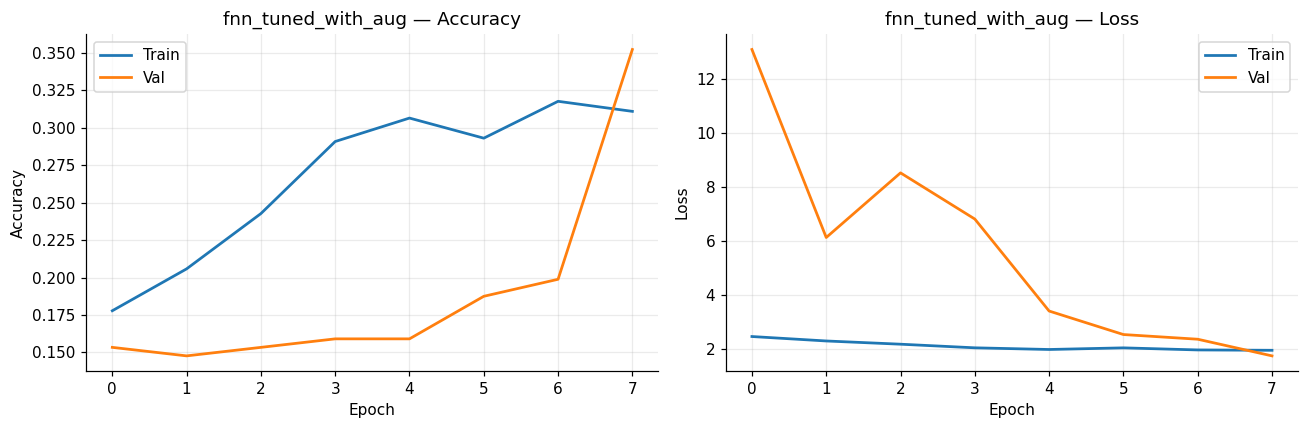

[fnn_tuned_with_aug] Val Acc: 35.23% (95% CI 28.6%-42.5%) | Val Loss: 1.7410 | Best Epoch: 8/8 | Params: 6,460,679 (31s)

Melatih Model: fnn_tuned_96_no_aug
Epoch 1/30


28/28 - 9s - 314ms/step - accuracy: 0.4251 - loss: 1.7766 - top2: 0.6879 - val_accuracy: 0.1591 - val_loss: 51.5212 - val_top2: 0.3011 - learning_rate: 5.0000e-04


Epoch 2/30


28/28 - 6s - 225ms/step - accuracy: 0.5850 - loss: 1.3156 - top2: 0.8255 - val_accuracy: 0.1591 - val_loss: 32.5147 - val_top2: 0.3011 - learning_rate: 5.0000e-04


Epoch 3/30


28/28 - 6s - 231ms/step - accuracy: 0.6174 - loss: 1.1981 - top2: 0.8512 - val_accuracy: 0.1591 - val_loss: 21.1860 - val_top2: 0.3011 - learning_rate: 5.0000e-04


... (10 outputs left out)


Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.


28/28 - 9s - 306ms/step - accuracy: 0.7852 - loss: 0.7802 - top2: 0.9407 - val_accuracy: 0.3807 - val_loss: 2.3532 - val_top2: 0.5682 - learning_rate: 2.5000e-04


Epoch 8: early stopping


Restoring model weights from the end of the best epoch: 1.


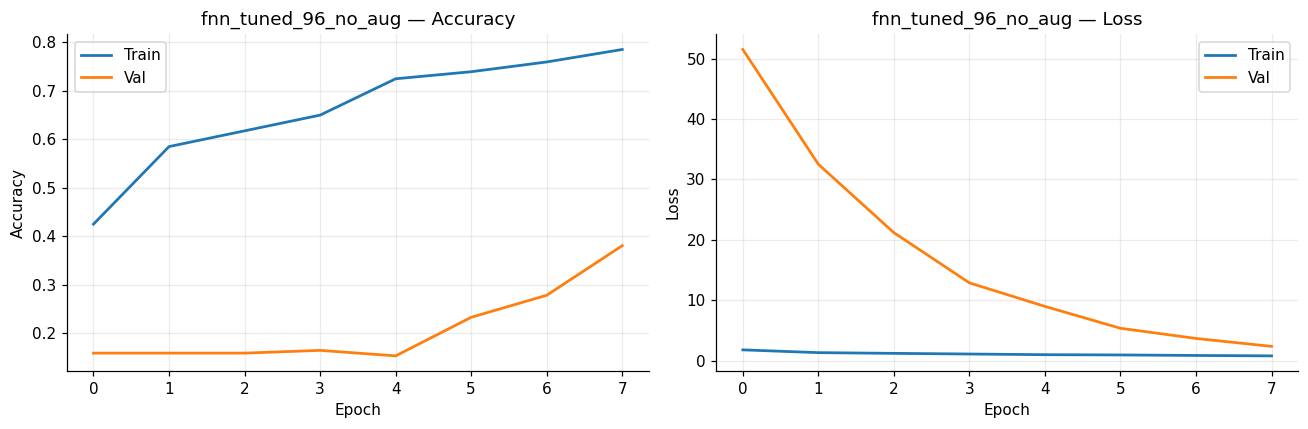

[fnn_tuned_96_no_aug] Val Acc: 38.07% (95% CI 31.2%-45.4%) | Val Loss: 2.3532 | Best Epoch: 8/8 | Params: 14,292,487 (65s)

Melatih Model: fnn_tuned_96_with_aug


Epoch 1/30


28/28 - 17s - 612ms/step - accuracy: 0.2338 - loss: 2.3261 - top2: 0.4139 - val_accuracy: 0.1534 - val_loss: 15.5082 - val_top2: 0.3466 - learning_rate: 5.0000e-04


Epoch 2/30


28/28 - 7s - 260ms/step - accuracy: 0.2919 - loss: 2.1215 - top2: 0.4676 - val_accuracy: 0.1534 - val_loss: 11.1795 - val_top2: 0.3011 - learning_rate: 5.0000e-04


Epoch 3/30


... (11 outputs left out)


Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.


28/28 - 7s - 234ms/step - accuracy: 0.3803 - loss: 1.8166 - top2: 0.5872 - val_accuracy: 0.3295 - val_loss: 1.9270 - val_top2: 0.5739 - learning_rate: 2.5000e-04


Epoch 8: early stopping


Restoring model weights from the end of the best epoch: 1.


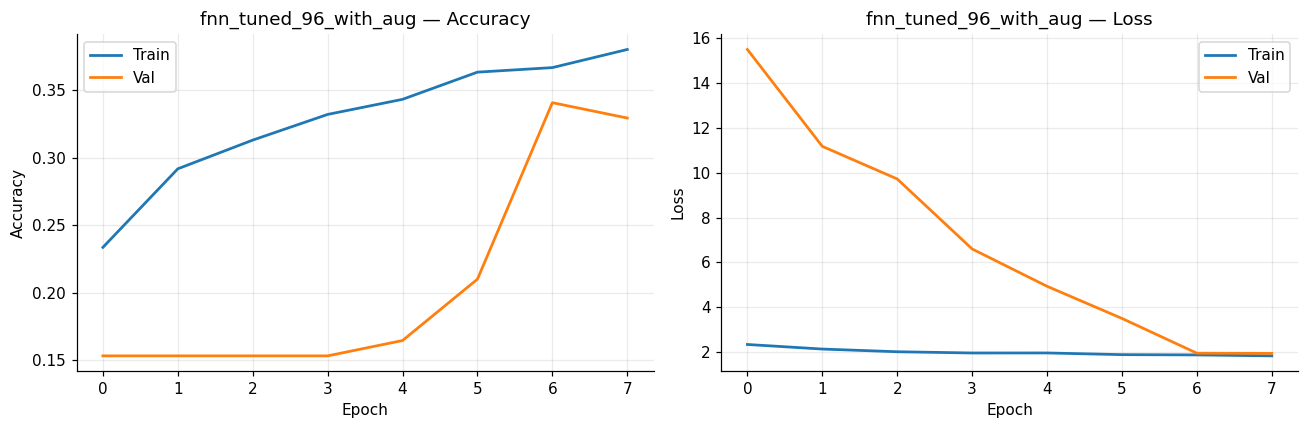

[fnn_tuned_96_with_aug] Val Acc: 34.09% (95% CI 27.5%-41.4%) | Val Loss: 1.9270 | Best Epoch: 7/8 | Params: 14,292,487 (66s)


In [9]:
L2_REG = 1e-4

def build_fnn_tuned(img_resize, hidden_units, dropout_rate, with_aug, name):
    inp = tf.keras.Input(shape=(*IMG_SIZE, 3), name='input')
    x = layers.Resizing(*img_resize, antialias=True, name='resizing')(inp)
    if with_aug:
        x = build_augmentation()(x)
    x = layers.Rescaling(1./255, name='rescaling')(x)
    x = layers.Flatten(name='flatten')(x)
    for i, units in enumerate(hidden_units):
        x = layers.Dense(units, activation=None,
                         kernel_regularizer=regularizers.l2(L2_REG),
                         name=f'dense_{units}_{i}')(x)
        x = layers.BatchNormalization(name=f'bn_{i}')(x)
        x = layers.Activation('relu', name=f'relu_{i}')(x)
        x = layers.Dropout(dropout_rate, name=f'dropout_{i}')(x)
    out = layers.Dense(len(CLASSES), activation='softmax', name='output')(x)
    model = tf.keras.Model(inp, out, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(cfg.tuning_lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=2, name='top2')])
    return model

tuned_configs = [
    dict(img_resize=(64, 64), hidden_units=(512, 256, 128), dropout_rate=0.4,
         with_aug=False, name='fnn_tuned_no_aug'),
    dict(img_resize=(64, 64), hidden_units=(512, 256, 128), dropout_rate=0.4,
         with_aug=True,  name='fnn_tuned_with_aug'),
    dict(img_resize=(96, 96), hidden_units=(512, 256), dropout_rate=0.4,
         with_aug=False, name='fnn_tuned_96_no_aug'),
    dict(img_resize=(96, 96), hidden_units=(512, 256), dropout_rate=0.4,
         with_aug=True,  name='fnn_tuned_96_with_aug'),
]

callbacks_tuned = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=cfg.patience,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, verbose=1),
]

epochs_tu = 2 if cfg.quick_test else cfg.tuning_epochs

for c in tuned_configs:
    nm = c['name']
    print(f'\n============================================================')
    print(f'Melatih Model: {nm}')
    print(f'============================================================')
    tf.keras.utils.set_random_seed(SEED)
    m = build_fnn_tuned(**c)
    t0 = time.time()
    hist = m.fit(
        train_ds, validation_data=val_ds,
        epochs=epochs_tu,
        callbacks=callbacks_tuned,
        class_weight=CLASS_WEIGHT if USE_CLASS_WEIGHT else None,
        verbose=2)
    train_sec = time.time() - t0

    plot_history(hist, nm, RESULTS)
    pd.DataFrame(hist.history).to_csv(RESULTS / f'history_{nm}.csv', index=False)

    val_acc = float(max(hist.history['val_accuracy']))
    val_top2 = float(max(hist.history['val_top2']))
    val_loss = float(min(hist.history['val_loss']))
    best_ep = int(np.argmax(hist.history['val_accuracy'])) + 1
    ep_ran = len(hist.history['val_accuracy'])
    n_params = m.count_params()
    lo, hi = wilson_ci(round(val_acc * N_VAL), N_VAL)

    print(f'[{nm}] Val Acc: {val_acc:.2%} (95% CI {lo:.1%}-{hi:.1%}) | Val Loss: {val_loss:.4f} | '
          f'Best Epoch: {best_ep}/{ep_ran} | Params: {n_params:,} ({train_sec:.0f}s)')

    runs[nm] = {
        'model': m, 'history': hist,
        'val_accuracy': val_acc, 'val_top2': val_top2, 'val_loss': val_loss,
        'best_epoch': best_ep, 'epochs_ran': ep_ran,
        'n_params': n_params, 'train_sec': train_sec,
        'val_ci': (lo, hi), 'augmentation': c['with_aug'], 'name': nm,
    }

### 8.1. Tabel Perbandingan Model & Pemilihan Model Terbaik

=== Tabel Perbandingan Hasil Validasi Seluruh Eksperimen FNN ===


,name,augmentation,val_accuracy,val_ci_low,val_ci_high,val_top2,val_loss,epochs_ran,best_epoch,n_params,train_sec,model_mb
0,fnn_tuned_no_aug,False,0.5682,0.4943,0.6391,0.7102,1.6018,26,18,6460679,86.3219,24.6455
1,fnn_tuned_96_no_aug,False,0.3807,0.3122,0.4542,0.5682,2.3532,8,8,14292487,64.6427,54.5215
2,fnn_baseline_paper,False,0.3750,0.3069,0.4485,0.5625,1.8758,15,11,19268615,97.9754,73.5039
3,fnn_tuned_with_aug,True,0.3523,0.2855,0.4253,0.5739,1.7410,8,8,6460679,30.5050,24.6455
4,fnn_tuned_96_with_aug,True,0.3409,0.2749,0.4137,0.5739,1.9270,8,7,14292487,65.8645,54.5215



Model Terpilih: fnn_tuned_no_aug
  Val Accuracy : 56.82% (95% CI 49.4% - 63.9%)
  Val Loss     : 1.6018
  Parameters   : 6,460,679
  Alasan       : Val accuracy tertinggi / dalam rentang toleransi noise 3% dengan val_loss terendah & parameter efisien.


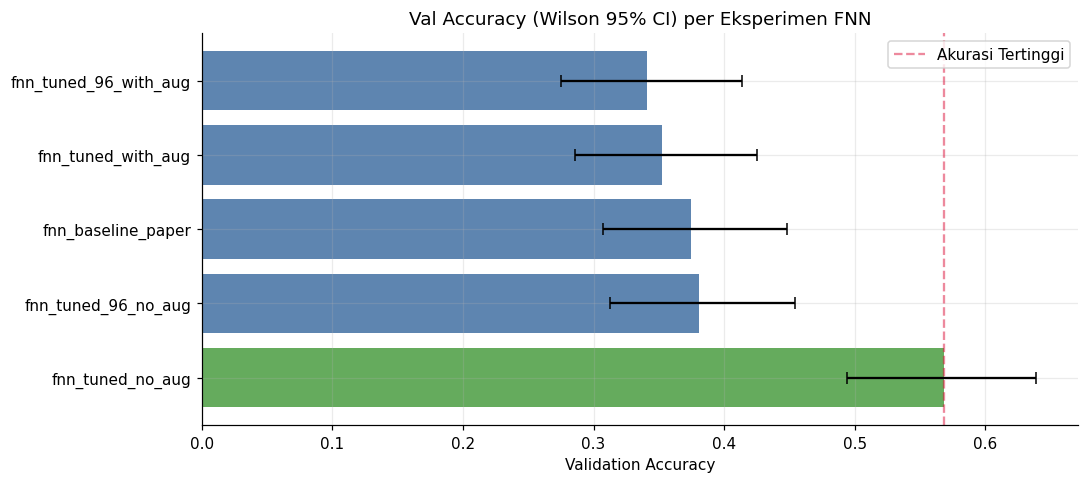

In [10]:
rows = []
for nm, r in runs.items():
    lo, hi = r['val_ci']
    rows.append({
        'name': nm,
        'augmentation': r['augmentation'],
        'val_accuracy': r['val_accuracy'],
        'val_ci_low': lo, 'val_ci_high': hi,
        'val_top2': r['val_top2'],
        'val_loss': r['val_loss'],
        'epochs_ran': r['epochs_ran'],
        'best_epoch': r['best_epoch'],
        'n_params': r['n_params'],
        'train_sec': r['train_sec'],
        'model_mb': r['n_params'] * 4 / (1024**2),
    })

compare = pd.DataFrame(rows).sort_values('val_accuracy', ascending=False).reset_index(drop=True)
print('=== Tabel Perbandingan Hasil Validasi Seluruh Eksperimen FNN ===')
display(compare[['name', 'augmentation', 'val_accuracy', 'val_ci_low', 'val_ci_high',
                 'val_top2', 'val_loss', 'epochs_ran', 'best_epoch', 'n_params', 'train_sec', 'model_mb']].round(4))
compare.to_csv(RESULTS / 'experiment_comparison.csv', index=False)

# Logika seleksi
best_acc = compare.val_accuracy.max()
candidates = compare[compare.val_accuracy >= best_acc - 0.03].copy()
best_row = candidates.sort_values(['val_accuracy', 'val_loss', 'n_params'], ascending=[False, True, True]).iloc[0]
best_name = best_row['name']
best_model = runs[best_name]['model']

print(f'\nModel Terpilih: {best_name}')
print(f'  Val Accuracy : {best_row.val_accuracy:.2%} (95% CI {best_row.val_ci_low:.1%} - {best_row.val_ci_high:.1%})')
print(f'  Val Loss     : {best_row.val_loss:.4f}')
print(f'  Parameters   : {int(best_row.n_params):,}')
print('  Alasan       : Val accuracy tertinggi / dalam rentang toleransi noise 3% dengan val_loss terendah & parameter efisien.')

# Visualisasi Confidence Interval
fig, ax = plt.subplots(figsize=(10, 4.5))
y_pos = np.arange(len(compare))
ax.barh(y_pos, compare.val_accuracy,
        xerr=[compare.val_accuracy - compare.val_ci_low, compare.val_ci_high - compare.val_accuracy],
        color=['#54A24B' if n == best_name else '#4C78A8' for n in compare.name],
        capsize=4, alpha=0.9)
ax.set_yticks(y_pos)
ax.set_yticklabels(compare.name)
ax.set(title='Val Accuracy (Wilson 95% CI) per Eksperimen FNN', xlabel='Validation Accuracy')
ax.axvline(best_acc, color='crimson', ls='--', alpha=0.5, label='Akurasi Tertinggi')
ax.legend()
plt.tight_layout()
fig.savefig(RESULTS / 'experiment_ci_comparison.png', dpi=150)
plt.show()

Evaluasi Model Terpilih pada VALIDATION SET (fnn_tuned_no_aug):


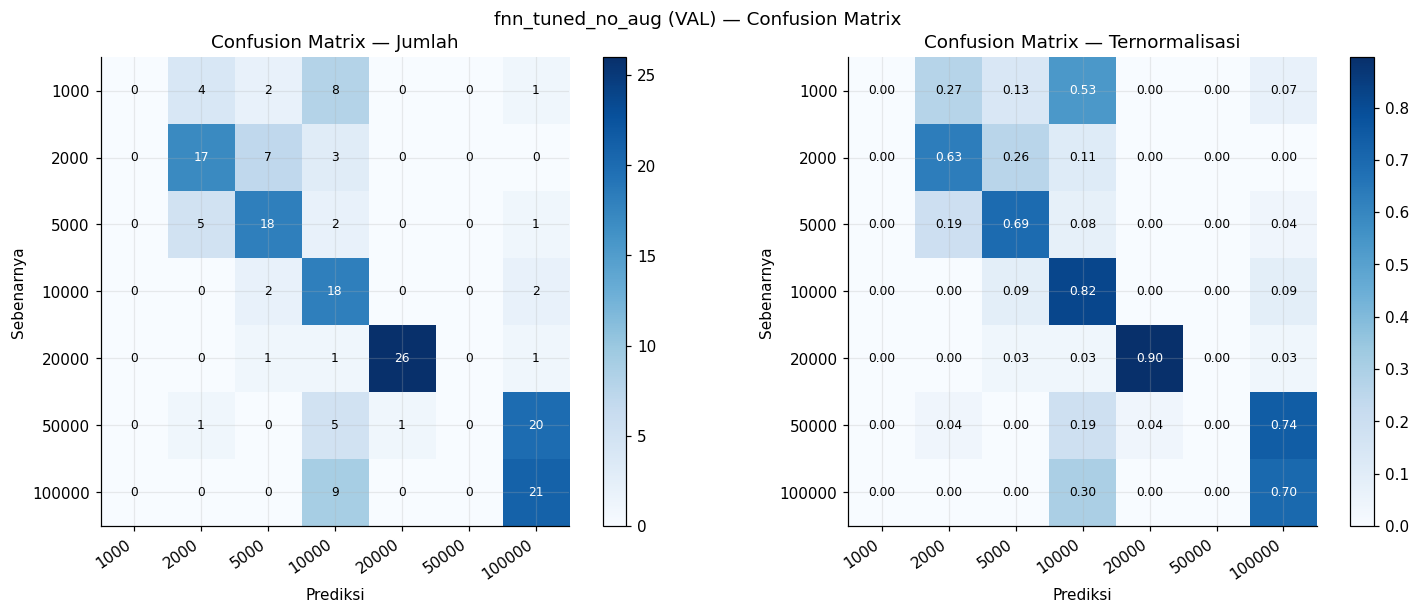


Classification Report (fnn_tuned_no_aug (VAL)):
              precision    recall  f1-score   support

    idr_1000       0.00      0.00      0.00        15
    idr_2000       0.63      0.63      0.63        27
    idr_5000       0.60      0.69      0.64        26
   idr_10000       0.39      0.82      0.53        22
   idr_20000       0.96      0.90      0.93        29
   idr_50000       0.00      0.00      0.00        27
  idr_100000       0.46      0.70      0.55        30

    accuracy                           0.57       176
   macro avg       0.43      0.53      0.47       176
weighted avg       0.47      0.57      0.50       176



In [11]:
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_and_save(model, ds, paths, tag, title_prefix):
    y_true = np.concatenate([b.numpy() for _, b in ds])
    y_prob = model.predict(ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
    report = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True)

    pred_df = pd.DataFrame({
        'path': paths,
        'true': [CLASSES[i] for i in y_true],
        'pred': [CLASSES[i] for i in y_pred],
        'confidence': y_prob.max(axis=1),
        'correct': y_true == y_pred,
    })

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    for ax, norm, title in zip(axes, [None, 'true'], ['Jumlah', 'Ternormalisasi']):
        data = cm.astype(float)
        if norm == 'true':
            data = data / (data.sum(axis=1, keepdims=True) + 1e-9)
        im = ax.imshow(data, cmap='Blues', vmin=0, vmax=data.max())
        ax.set_xticks(range(len(CLASSES)))
        ax.set_yticks(range(len(CLASSES)))
        ax.set_xticklabels([c.replace('idr_', '') for c in CLASSES], rotation=35, ha='right')
        ax.set_yticklabels([c.replace('idr_', '') for c in CLASSES])
        ax.set(xlabel='Prediksi', ylabel='Sebenarnya', title=f'Confusion Matrix - {title}')
        for i in range(len(CLASSES)):
            for j in range(len(CLASSES)):
                val_txt = f'{data[i, j]:.2f}' if norm else f'{cm[i, j]}'
                ax.text(j, i, val_txt, ha='center', va='center', fontsize=8,
                        color='white' if data[i, j] > data.max() * 0.55 else 'black')
        plt.colorbar(im, ax=ax)
    plt.suptitle(f'{title_prefix} - Confusion Matrix', fontsize=12)
    plt.tight_layout()
    fig.savefig(RESULTS / f'cm_{tag}.png', dpi=150)
    plt.show()

    print(f'\nClassification Report ({title_prefix}):')
    print(classification_report(y_true, y_pred, target_names=CLASSES))
    return {'y_true': y_true, 'y_pred': y_pred, 'y_prob': y_prob, 'cm': cm,
            'report': report, 'pred_df': pred_df}

print(f'Evaluasi Model Terpilih pada VALIDATION SET ({best_name}):')
val_eval = evaluate_and_save(best_model, val_ds, val_paths, 'val_selected', f'{best_name} (VAL)')

## 9. Evaluasi Final pada Test Set (n=179)

=== HASIL TEST SET FINAL (fnn_tuned_no_aug, n=179) ===
  Test Accuracy : 58.66% (95% Wilson CI: 51.3% - 65.6%)
  Test Top-2    : 75.42%
  Test Loss     : 1.5935


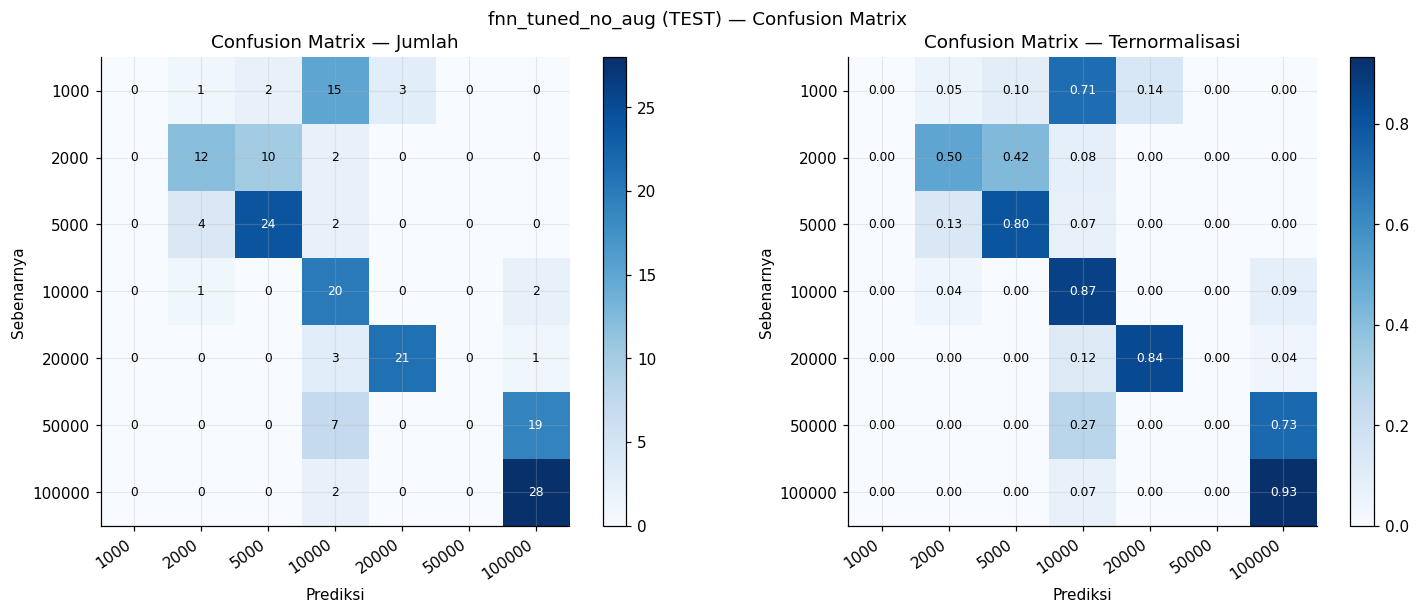


Classification Report (fnn_tuned_no_aug (TEST)):
              precision    recall  f1-score   support

    idr_1000       0.00      0.00      0.00        21
    idr_2000       0.67      0.50      0.57        24
    idr_5000       0.67      0.80      0.73        30
   idr_10000       0.39      0.87      0.54        23
   idr_20000       0.88      0.84      0.86        25
   idr_50000       0.00      0.00      0.00        26
  idr_100000       0.56      0.93      0.70        30

    accuracy                           0.59       179
   macro avg       0.45      0.56      0.49       179
weighted avg       0.47      0.59      0.50       179



Model final disimpan ke: results\fnn_selected_final.keras


In [12]:
test_loss, test_acc, test_top2 = best_model.evaluate(test_ds, verbose=0)
t_lo, t_hi = wilson_ci(round(test_acc * N_TEST), N_TEST)

print(f'=== HASIL TEST SET FINAL ({best_name}, n={N_TEST}) ===')
print(f'  Test Accuracy : {test_acc:.2%} (95% Wilson CI: {t_lo:.1%} - {t_hi:.1%})')
print(f'  Test Top-2    : {test_top2:.2%}')
print(f'  Test Loss     : {test_loss:.4f}')

test_eval = evaluate_and_save(best_model, test_ds, test_paths, 'test_selected', f'{best_name} (TEST)')

# Simpan model final
best_model_path = RESULTS / 'fnn_selected_final.keras'
try:
    best_model.save(best_model_path, include_optimizer=False)
except TypeError:
    best_model.save(best_model_path)
print(f'Model final disimpan ke: {best_model_path}')

Metrik Makro Test: Precision=0.4515 | Recall=0.5633 | F1-Score=0.4852

Pasangan kelas yang paling sering tertukar pada test set:


,sebenarnya,diprediksi,jumlah
13,idr_50000,idr_100000,19
2,idr_1000,idr_10000,15
4,idr_2000,idr_5000,10
12,idr_50000,idr_10000,7
6,idr_5000,idr_2000,4
3,idr_1000,idr_20000,3
10,idr_20000,idr_10000,3
1,idr_1000,idr_5000,2
5,idr_2000,idr_10000,2
7,idr_5000,idr_10000,2


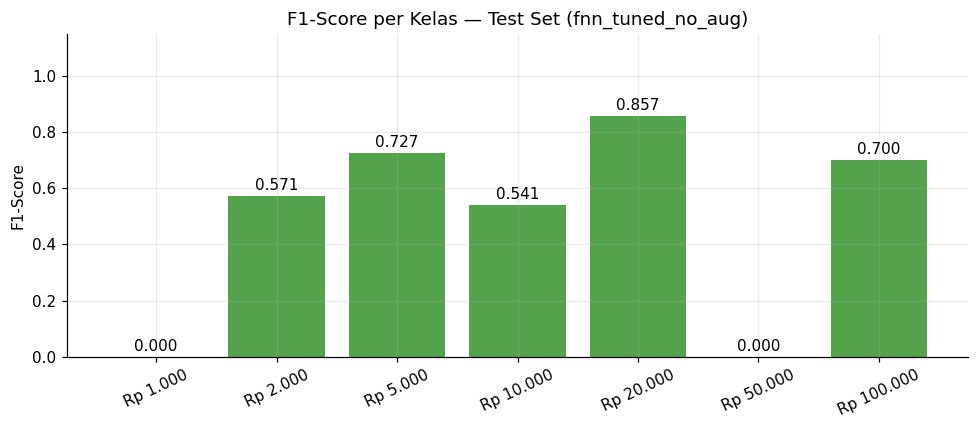

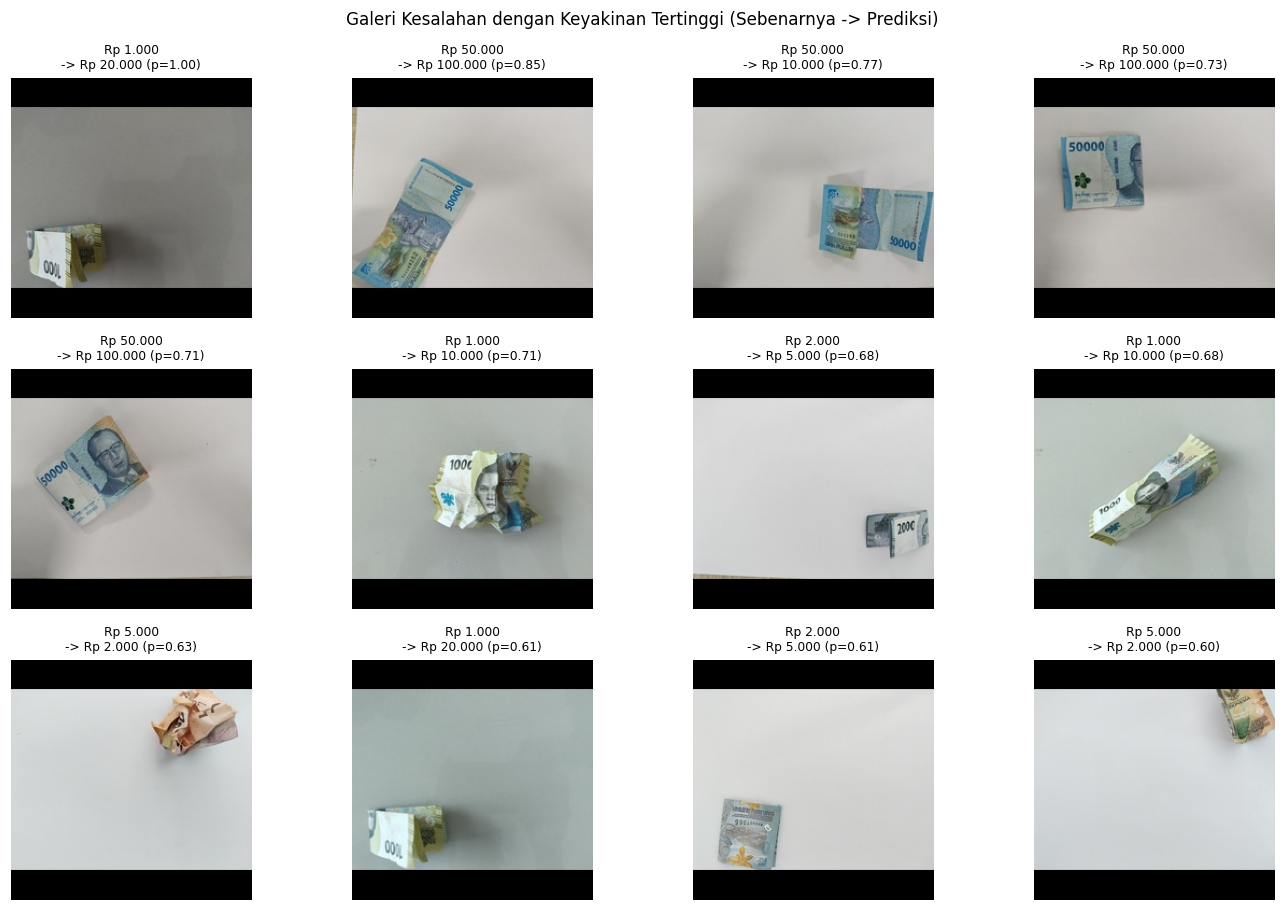

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

yt, yp = test_eval['y_true'], test_eval['y_pred']
mac_p = precision_score(yt, yp, average='macro', zero_division=0)
mac_r = recall_score(yt, yp, average='macro', zero_division=0)
mac_f = f1_score(yt, yp, average='macro', zero_division=0)
print(f'Metrik Makro Test: Precision={mac_p:.4f} | Recall={mac_r:.4f} | F1-Score={mac_f:.4f}')

# Pasangan paling sering tertukar
cm_test = test_eval['cm']
conf_pairs = []
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if i != j and cm_test[i, j] > 0:
            conf_pairs.append((CLASSES[i], CLASSES[j], int(cm_test[i, j])))
conf_df = pd.DataFrame(conf_pairs, columns=['sebenarnya', 'diprediksi', 'jumlah']).sort_values('jumlah', ascending=False)
print('\nPasangan kelas yang paling sering tertukar pada test set:')
display(conf_df.head(10) if len(conf_df) else 'Tidak ada kesalahan prediksi.')

# Bar chart F1 per kelas
f1_per_class = pd.Series({pretty(c): test_eval['report'][c]['f1-score'] for c in CLASSES})
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(f1_per_class.index, f1_per_class.values, color='#54A24B')
ax.bar_label(bars, fmt='%.3f', padding=2)
ax.set(title=f'F1-Score per Kelas - Test Set ({best_name})', ylabel='F1-Score', ylim=(0, 1.15))
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
fig.savefig(RESULTS / 'final_test_f1_per_class.png', dpi=150)
plt.show()

# Galeri 12 kesalahan dengan keyakinan tertinggi
wrong = test_eval['pred_df'][~test_eval['pred_df'].correct].sort_values('confidence', ascending=False).head(12)
if len(wrong):
    ncols = min(4, len(wrong))
    nrows = math.ceil(len(wrong) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.2, nrows * 2.8), squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax, r in zip(axes.flat, wrong.itertuples()):
        with Image.open(r.path) as im:
            ax.imshow(im)
        ax.set_title(f'{pretty(r.true)}\n-> {pretty(r.pred)} (p={r.confidence:.2f})', fontsize=8)
    plt.suptitle('Galeri Kesalahan dengan Keyakinan Tertinggi (Sebenarnya -> Prediksi)', fontsize=11)
    plt.tight_layout()
    fig.savefig(RESULTS / 'final_test_error_gallery.png', dpi=150)
    plt.show()
else:
    print('Sempurna: Tidak ada kesalahan pada test set.')

## 10. Uji Ketahanan Pencahayaan (Lighting Robustness)

Kondisi gelap (0.75x)  : Accuracy=17.32% (95% CI 12.5%-23.5%) | Top-2=47.49%


Kondisi normal (1.00x) : Accuracy=58.66% (95% CI 51.3%-65.6%) | Top-2=75.42%


Kondisi terang (1.25x) : Accuracy=16.76% (95% CI 12.0%-22.9%) | Top-2=30.73%


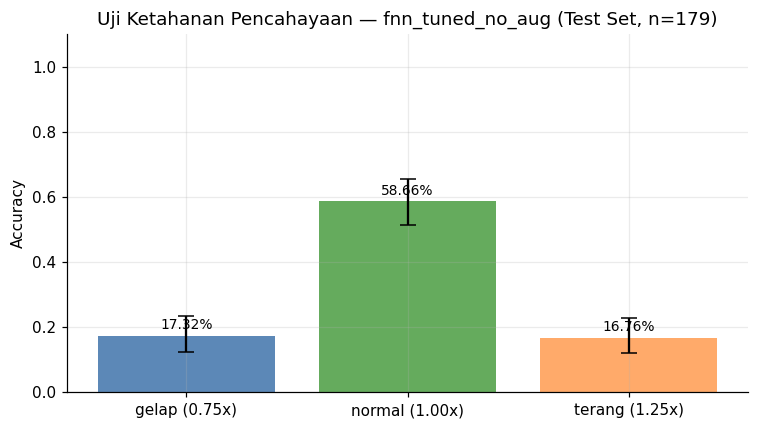

In [14]:
def make_brightness_ds(factor):
    def _map(img, lbl):
        img_f = tf.cast(img, tf.float32)
        img_f = tf.clip_by_value(img_f * factor, 0.0, 255.0)
        return img_f, lbl
    return test_ds.unbatch().map(_map, num_parallel_calls=AUTOTUNE).batch(cfg.batch_size).prefetch(AUTOTUNE)

lighting_results = {}
for cond, factor in [('gelap (0.75x)', 0.75), ('normal (1.00x)', 1.00), ('terang (1.25x)', 1.25)]:
    b_ds = make_brightness_ds(factor)
    b_loss, b_acc, b_top2 = best_model.evaluate(b_ds, verbose=0)
    b_lo, b_hi = wilson_ci(round(b_acc * N_TEST), N_TEST)
    lighting_results[cond] = {
        'factor': factor, 'accuracy': b_acc, 'top2': b_top2, 'loss': b_loss,
        'ci': (b_lo, b_hi)
    }
    print(f'Kondisi {cond:<15}: Accuracy={b_acc:.2%} (95% CI {b_lo:.1%}-{b_hi:.1%}) | Top-2={b_top2:.2%}')

# Visualisasi uji pencahayaan
fig, ax = plt.subplots(figsize=(7, 4))
cond_names = list(lighting_results.keys())
cond_accs = [lighting_results[k]['accuracy'] for k in cond_names]
cond_err_lo = [lighting_results[k]['accuracy'] - lighting_results[k]['ci'][0] for k in cond_names]
cond_err_hi = [lighting_results[k]['ci'][1] - lighting_results[k]['accuracy'] for k in cond_names]

bars = ax.bar(cond_names, cond_accs, yerr=[cond_err_lo, cond_err_hi],
              color=['#4A7BB0', '#54A24B', '#FFA15A'], capsize=5, alpha=0.9)
for b, a in zip(bars, cond_accs):
    ax.text(b.get_x() + b.get_width() / 2, a + 0.02, f'{a:.2%}', ha='center', fontsize=9)
ax.set(title=f'Uji Ketahanan Pencahayaan - {best_name} (Test Set, n={N_TEST})',
       ylabel='Accuracy', ylim=(0, 1.1))
plt.tight_layout()
fig.savefig(RESULTS / 'lighting_robustness.png', dpi=150)
plt.show()

## 11. Perbandingan Komparatif Lintas Arsitektur (CNN vs MobileNetV2 vs FNN)

In [15]:
cross_table_data = [
    {
        'Model': 'Custom CNN (tuned_with_aug)',
        'Arsitektur': '4 Blok Conv2D + BN + MaxPool + Dense',
        'Test Accuracy': '99.44%',
        '95% CI': '96.9% - 99.9%',
        'Macro F1': '0.9944',
        'Top-2 Acc': '100.0%',
        'Sumber': 'Output Rupiah_CustomCNN.ipynb'
    },
    {
        'Model': 'MobileNetV2 Transfer Learning',
        'Arsitektur': 'Pretrained ImageNet + Fine-tuning',
        'Test Accuracy': '95.53%',
        '95% CI': '91.4% - 97.7%',
        'Macro F1': '0.9547',
        'Top-2 Acc': '98.88%',
        'Sumber': 'Output mobilenetv2-training-kaggle.ipynb'
    },
    {
        'Model': f'FNN ({best_name})',
        'Arsitektur': 'Flatten + Dense MLP (tanpa konvolusi)',
        'Test Accuracy': f'{test_acc:.2%}',
        '95% CI': f'{t_lo:.1%} - {t_hi:.1%}',
        'Macro F1': f'{mac_f:.4f}',
        'Top-2 Acc': f'{test_top2:.2%}',
        'Sumber': 'Hasil eksekusi notebook ini'
    },
    {
        'Model': 'FNN Paper (Aprillia dkk., 2024)*',
        'Arsitektur': 'Flatten + Dense(128) + Dense(7)',
        'Test Accuracy': '53.57%',
        '95% CI': 'N/A',
        'Macro F1': 'N/A',
        'Top-2 Acc': 'N/A',
        'Sumber': 'Paper KLIK 4(4) 2024'
    }
]

cross_df = pd.DataFrame(cross_table_data)
print('=== Tabel Perbandingan Kinerja Lintas Model pada Test Set Rupiah ===')
display(cross_df)

print('\nCatatan Komparasi:')
print('* FNN Paper (Aprillia dkk., 2024) menggunakan protokol yang berbeda:')
print('  - Augmentasi dilakukan sebelum train-test split (potensi leakage besar).')
print('  - Hanya berbasis 14 citra sumber asli.')
print('  - Oleh karena itu, angka FNN Paper tidak sebanding langsung secara metodologis, namun membuktikan bahwa FNN murni pada citra uang kertas memang menghadapi batas kinerja yang rendah.')

=== Tabel Perbandingan Kinerja Lintas Model pada Test Set Rupiah ===


,Model,Arsitektur,Test Accuracy,95% CI,Macro F1,Top-2 Acc,Sumber
0,Custom CNN (tuned_with_aug),4 Blok Conv2D + BN + MaxPool + Dense,99.44%,96.9% - 99.9%,0.9944,100.0%,Output Rupiah_CustomCNN.ipynb
1,MobileNetV2 Transfer Learning,Pretrained ImageNet + Fine-tuning,95.53%,91.4% - 97.7%,0.9547,98.88%,Output mobilenetv2-training-kaggle.ipynb
2,FNN (fnn_tuned_no_aug),Flatten + Dense MLP (tanpa konvolusi),58.66%,51.3% - 65.6%,0.4852,75.42%,Hasil eksekusi notebook ini
3,"FNN Paper (Aprillia dkk., 2024)*",Flatten + Dense(128) + Dense(7),53.57%,N/A,N/A,N/A,Paper KLIK 4(4) 2024



Catatan Komparasi:
* FNN Paper (Aprillia dkk., 2024) menggunakan protokol yang berbeda:
  - Augmentasi dilakukan sebelum train-test split (potensi leakage besar).
  - Hanya berbasis 14 citra sumber asli.
  - Oleh karena itu, angka FNN Paper tidak sebanding langsung secara metodologis, namun membuktikan bahwa FNN murni pada citra uang kertas memang menghadapi batas kinerja yang rendah.
